# Do stated-preference segments choose differently?

## Research question
Do participants who report different partner-trait priorities also make choices based on different partner traits?

This notebook follows the segment-first approach:
1. Form participant segments from pre-event stated trait preferences.
2. Fit conditional logistic choice models within each gender-by-segment group.
3. Use a pooled interaction test to assess whether the trait-choice relationships differ between segments.

The yes/no outcome is each participant's decision for a particular date. The six predictors are their ratings of that date partner. The model uses participant fixed effects through conditional likelihood, so it focuses on how a participant's ratings vary across their own dates.

The segments are formed without using the yes/no outcomes. This lets us ask whether groups defined by stated preferences also show different revealed-choice patterns.


## 1. Load the cleaned data

Place the cleaned unscaled CSV in the same folder as this notebook, or update DATA_PATH below. In this project environment, the code also checks the uploaded-data path.

Required packages: pandas, numpy, scikit-learn, scipy, and matplotlib.


In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.stats import chi2

DATA_PATH = Path("Speed Dating cleaned unscaled.csv")
if not DATA_PATH.exists():
    project_copy = Path("/workspace/scratch/7308692dcc46/upload/Speed Dating cleaned unscaled.csv")
    if project_copy.exists():
        DATA_PATH = project_copy

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find Speed Dating cleaned unscaled.csv. "
        "Put the CSV beside this notebook or update DATA_PATH."
    )

raw = pd.read_csv(DATA_PATH)
print(f"Loaded {raw.shape[0]:,} date rows and {raw.shape[1]:,} columns.")
print("Gender coding in this cleaned file: 0 = women, 1 = men.")


Loaded 8,378 date rows and 195 columns.
Gender coding in this cleaned file: 0 = women, 1 = men.


## 2. Create the stated-preference segments

Each participant is represented by six pre-event survey fields:
attr1_1, sinc1_1, intel1_1, fun1_1, amb1_1, and shar1_1.

We normalize each participant's six values to sum to 100, then cluster women and men separately using two-cluster K-means on the square-root-transformed preference shares. The cluster with the higher average stated attractiveness importance is labeled Attractiveness-led; the other is Broader preference mix.

These are descriptive labels for cluster averages. They do not mean every person in a segment has the same preferences.


In [2]:
STATED = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"]
TRAIT_NAMES = {
    "attr1_1": "Attractiveness",
    "sinc1_1": "Sincerity",
    "intel1_1": "Intelligence",
    "fun1_1": "Fun",
    "amb1_1": "Ambition",
    "shar1_1": "Shared interests",
}
GENDER_NAMES = {0: "Women", 1: "Men"}

prefs = (
    raw.groupby("iid")
       .agg(gender=("gender", "first"), **{c: (c, "first") for c in STATED})
       .dropna(subset=STATED)
       .copy()
)
pref_total = prefs[STATED].sum(axis=1)
prefs = prefs.loc[pref_total.gt(0)].copy()
prefs[STATED] = prefs[STATED].div(pref_total.loc[prefs.index], axis=0) * 100
prefs["segment"] = ""

for gender_code in [0, 1]:
    gender_prefs = prefs.loc[prefs["gender"].eq(gender_code)].copy()
    hellinger = np.sqrt(gender_prefs[STATED].to_numpy() / 100)
    labels = KMeans(n_clusters=2, random_state=42, n_init=100).fit_predict(hellinger)
    gender_prefs["cluster"] = labels
    cluster_means = gender_prefs.groupby("cluster")[STATED].mean()
    attraction_cluster = cluster_means["attr1_1"].idxmax()
    gender_prefs["segment"] = np.where(
        gender_prefs["cluster"].eq(attraction_cluster),
        "Attractiveness-led",
        "Broader preference mix",
    )
    prefs.loc[gender_prefs.index, "segment"] = gender_prefs["segment"]

prefs["gender_name"] = prefs["gender"].map(GENDER_NAMES)
profile = (
    prefs.groupby(["gender_name", "segment"])[STATED]
         .mean()
         .rename(columns=TRAIT_NAMES)
)
profile["participants"] = prefs.groupby(["gender_name", "segment"]).size()
print("Segment sizes and average stated-preference profiles (points out of 100):")
print(profile.round(1).to_string())


Segment sizes and average stated-preference profiles (points out of 100):
                                    Attractiveness  Sincerity  Intelligence   Fun  Ambition  Shared interests  participants
gender_name segment                                                                                                        
Men         Attractiveness-led                42.6       13.6          17.4  18.6       3.5               4.2            72
            Broader preference mix            21.4       17.3          20.1  17.2      10.6              13.3           201
Women       Attractiveness-led                31.6       13.3          22.9  17.6       9.2               5.5            50
            Broader preference mix            14.8       19.4          20.5  17.3      13.7              14.4           218


### Stated-preference profile plot

This plot shows the average survey importance assigned to each trait within each segment. It describes what the segments said they valued; the choice model below examines how those traits relate to actual yes/no decisions.


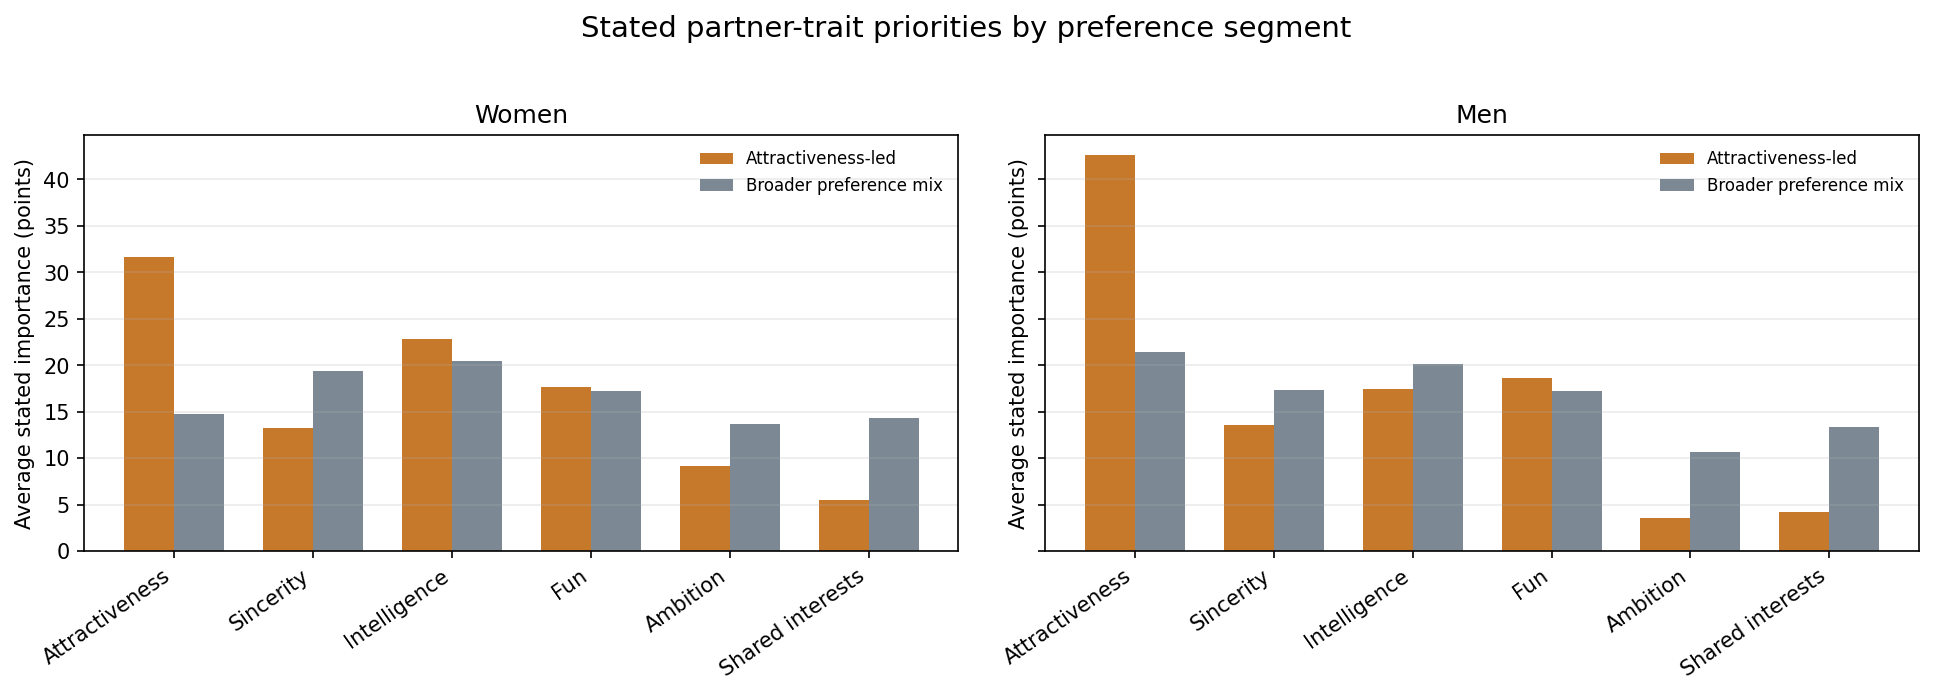

In [3]:
profile_plot = profile.reset_index()
traits = list(TRAIT_NAMES.values())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"Attractiveness-led": "#C7792B", "Broader preference mix": "#7C8995"}

for ax, gender_name in zip(axes, ["Women", "Men"]):
    part = profile_plot.loc[profile_plot["gender_name"].eq(gender_name)]
    x = np.arange(len(traits))
    width = 0.36
    for offset, segment in [(-width/2, "Attractiveness-led"), (width/2, "Broader preference mix")]:
        row = part.loc[part["segment"].eq(segment)].iloc[0]
        values = [row[t] for t in traits]
        ax.bar(x + offset, values, width=width, label=segment, color=colors[segment])
    ax.set_title(gender_name)
    ax.set_xticks(x)
    ax.set_xticklabels(traits, rotation=35, ha="right")
    ax.set_ylabel("Average stated importance (points)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Stated partner-trait priorities by preference segment", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()


## 3. Build the choice-model sample

We keep date rows with a recorded decision and all six partner ratings. Conditional logistic regression needs each participant to have at least one yes and one no in the retained rows; participants with only yes or only no do not identify the within-person rating effects and are excluded.

The segment label is then joined to each participant's date rows.


In [4]:
RATINGS = ["attr", "sinc", "intel", "fun", "amb", "shar"]
RATING_NAMES = {
    "attr": "Attractiveness",
    "sinc": "Sincerity",
    "intel": "Intelligence",
    "fun": "Fun",
    "amb": "Ambition",
    "shar": "Shared interests",
}

choice = raw.dropna(subset=["dec"] + RATINGS).copy()
decision_counts = choice.groupby("iid")["dec"].nunique()
eligible_iids = decision_counts.loc[decision_counts.eq(2)].index
choice = (
    choice.loc[choice["iid"].isin(eligible_iids)]
          .merge(prefs[["segment"]], left_on="iid", right_index=True, how="inner")
          .copy()
)
choice["gender_name"] = choice["gender"].map(GENDER_NAMES)

sample_summary = (
    choice.groupby(["gender_name", "segment"])
          .agg(
              participants=("iid", "nunique"),
              date_decisions=("dec", "size"),
              yes_rate=("dec", "mean"),
          )
          .reset_index()
)
print("Retained sample by gender and stated-preference segment:")
print(sample_summary.to_string(index=False, formatters={"yes_rate": "{:.1%}".format}))
print(f"Total: {choice['iid'].nunique():,} participants and {len(choice):,} date decisions.")


Retained sample by gender and stated-preference segment:
gender_name                segment  participants  date_decisions yes_rate
        Men     Attractiveness-led            56             774    45.2%
        Men Broader preference mix           173            2448    48.9%
      Women     Attractiveness-led            42             519    36.2%
      Women Broader preference mix           181            2481    40.3%
Total: 452 participants and 6,222 date decisions.


## 4. Conditional logistic regression

For each participant and date, the model relates the date-specific yes/no decision to the six ratings of that partner. Participant-level baseline willingness to say yes is controlled by conditioning on the participant's total number of yes decisions.

The coefficients below use ratings standardized within gender's retained sample. A coefficient is the change in log-odds associated with a one-standard-deviation increase in that partner rating, holding the other ratings constant.

For comparability with the existing analysis, we also convert positive coefficients into relative revealed-importance shares:
100 times max(beta, 0), divided by the sum of positive coefficients.
These shares are a summary of the model coefficients, not probabilities. A zero share means the coefficient was non-positive in that fit; it does not prove that a trait never matters.


In [5]:
def group_terms(X, y, beta):
    # Conditional log-likelihood and gradient for one participant stratum.
    eta = X @ beta
    n = len(y)
    m = int(round(y.sum()))

    # Dynamic-programming tables for the log elementary symmetric polynomial.
    forward = np.full((n + 1, m + 1), -np.inf)
    forward[0, 0] = 0.0
    for i in range(n):
        top = min(i + 1, m)
        forward[i + 1, 0] = 0.0
        if top:
            forward[i + 1, 1:top + 1] = np.logaddexp(
                forward[i, 1:top + 1],
                forward[i, :top] + eta[i],
            )

    backward = np.full((n + 1, m + 1), -np.inf)
    backward[n, 0] = 0.0
    for i in range(n - 1, -1, -1):
        top = min(n - i, m)
        backward[i, 0] = 0.0
        if top:
            backward[i, 1:top + 1] = np.logaddexp(
                backward[i + 1, 1:top + 1],
                backward[i + 1, :top] + eta[i],
            )

    log_denominator = forward[n, m]
    expected_yes = np.empty(n)
    for i in range(n):
        log_excluding_i = logsumexp(
            forward[i, :m] + backward[i + 1, m - 1::-1]
        )
        expected_yes[i] = np.exp(
            min(0.0, eta[i] + log_excluding_i - log_denominator)
        )

    log_likelihood = float(y @ eta - log_denominator)
    gradient = X.T @ (y - expected_yes)
    return log_likelihood, gradient


def make_groups(frame, feature_cols):
    # Return one design matrix and decision vector per participant.
    return [
        (g[feature_cols].to_numpy(float), g["dec"].to_numpy(float))
        for _, g in frame.groupby("iid", sort=False)
    ]


def fit_conditional_logit(groups, n_features):
    def objective(beta):
        total_ll = 0.0
        total_gradient = np.zeros(n_features)
        for X, y in groups:
            ll, gradient = group_terms(X, y, beta)
            total_ll += ll
            total_gradient += gradient
        return -total_ll, -total_gradient

    return minimize(
        objective,
        np.zeros(n_features),
        jac=True,
        method="L-BFGS-B",
        options={"maxiter": 400, "ftol": 1e-12, "gtol": 1e-8, "maxls": 40},
    )


def positive_importance_shares(beta):
    positive = np.maximum(beta, 0)
    if positive.sum() == 0:
        return np.full(len(beta), np.nan)
    return 100 * positive / positive.sum()


## 5. Fit one choice model per gender-by-segment group

All groups of a gender use the same rating standardization, so their coefficients are on comparable scales. The models are estimated separately for the two stated-preference segments within each gender.


In [6]:
scaled_by_gender = {}
segment_fits = {}
segment_rows = []

for gender_code, gender_name in GENDER_NAMES.items():
    gender_rows = choice.loc[choice["gender"].eq(gender_code)].copy()
    means = gender_rows[RATINGS].mean()
    sds = gender_rows[RATINGS].std(ddof=0)

    z_cols = []
    for rating in RATINGS:
        z_col = f"z_{rating}"
        gender_rows[z_col] = (gender_rows[rating] - means[rating]) / sds[rating]
        z_cols.append(z_col)

    scaled_by_gender[gender_code] = (gender_rows, z_cols)

    for segment in ["Attractiveness-led", "Broader preference mix"]:
        group_rows = gender_rows.loc[gender_rows["segment"].eq(segment)].copy()
        fitted = fit_conditional_logit(make_groups(group_rows, z_cols), len(z_cols))
        segment_fits[(gender_code, segment)] = fitted

        if not fitted.success:
            print(f"Warning: optimizer did not report convergence for {gender_name} / {segment}: {fitted.message}")

        betas = fitted.x
        shares = positive_importance_shares(betas)
        for trait, beta, share in zip(RATING_NAMES.values(), betas, shares):
            segment_rows.append({
                "gender": gender_name,
                "segment": segment,
                "participants": group_rows["iid"].nunique(),
                "date_decisions": len(group_rows),
                "yes_rate": group_rows["dec"].mean(),
                "trait": trait,
                "beta_per_gender_SD": beta,
                "relative_revealed_weight_pct": share,
                "log_likelihood": -fitted.fun,
            })

segment_results = pd.DataFrame(segment_rows)
print("Segment-specific conditional-logit coefficients and relative positive-weight shares:")
print(
    segment_results[
        ["gender", "segment", "participants", "date_decisions", "trait",
         "beta_per_gender_SD", "relative_revealed_weight_pct"]
    ].round(3).to_string(index=False)
)


Segment-specific conditional-logit coefficients and relative positive-weight shares:
gender                segment  participants  date_decisions            trait  beta_per_gender_SD  relative_revealed_weight_pct
 Women     Attractiveness-led            42             519   Attractiveness               1.474                        42.457
 Women     Attractiveness-led            42             519        Sincerity               0.336                         9.674
 Women     Attractiveness-led            42             519     Intelligence               0.080                         2.315
 Women     Attractiveness-led            42             519              Fun               0.528                        15.214
 Women     Attractiveness-led            42             519         Ambition              -0.087                         0.000
 Women     Attractiveness-led            42             519 Shared interests               1.054                        30.339
 Women Broader preference 

### Compare the relative revealed-importance shares

The shares make the segment patterns easier to compare. Use them as descriptive summaries; the coefficients and interaction test are the model-based quantities.


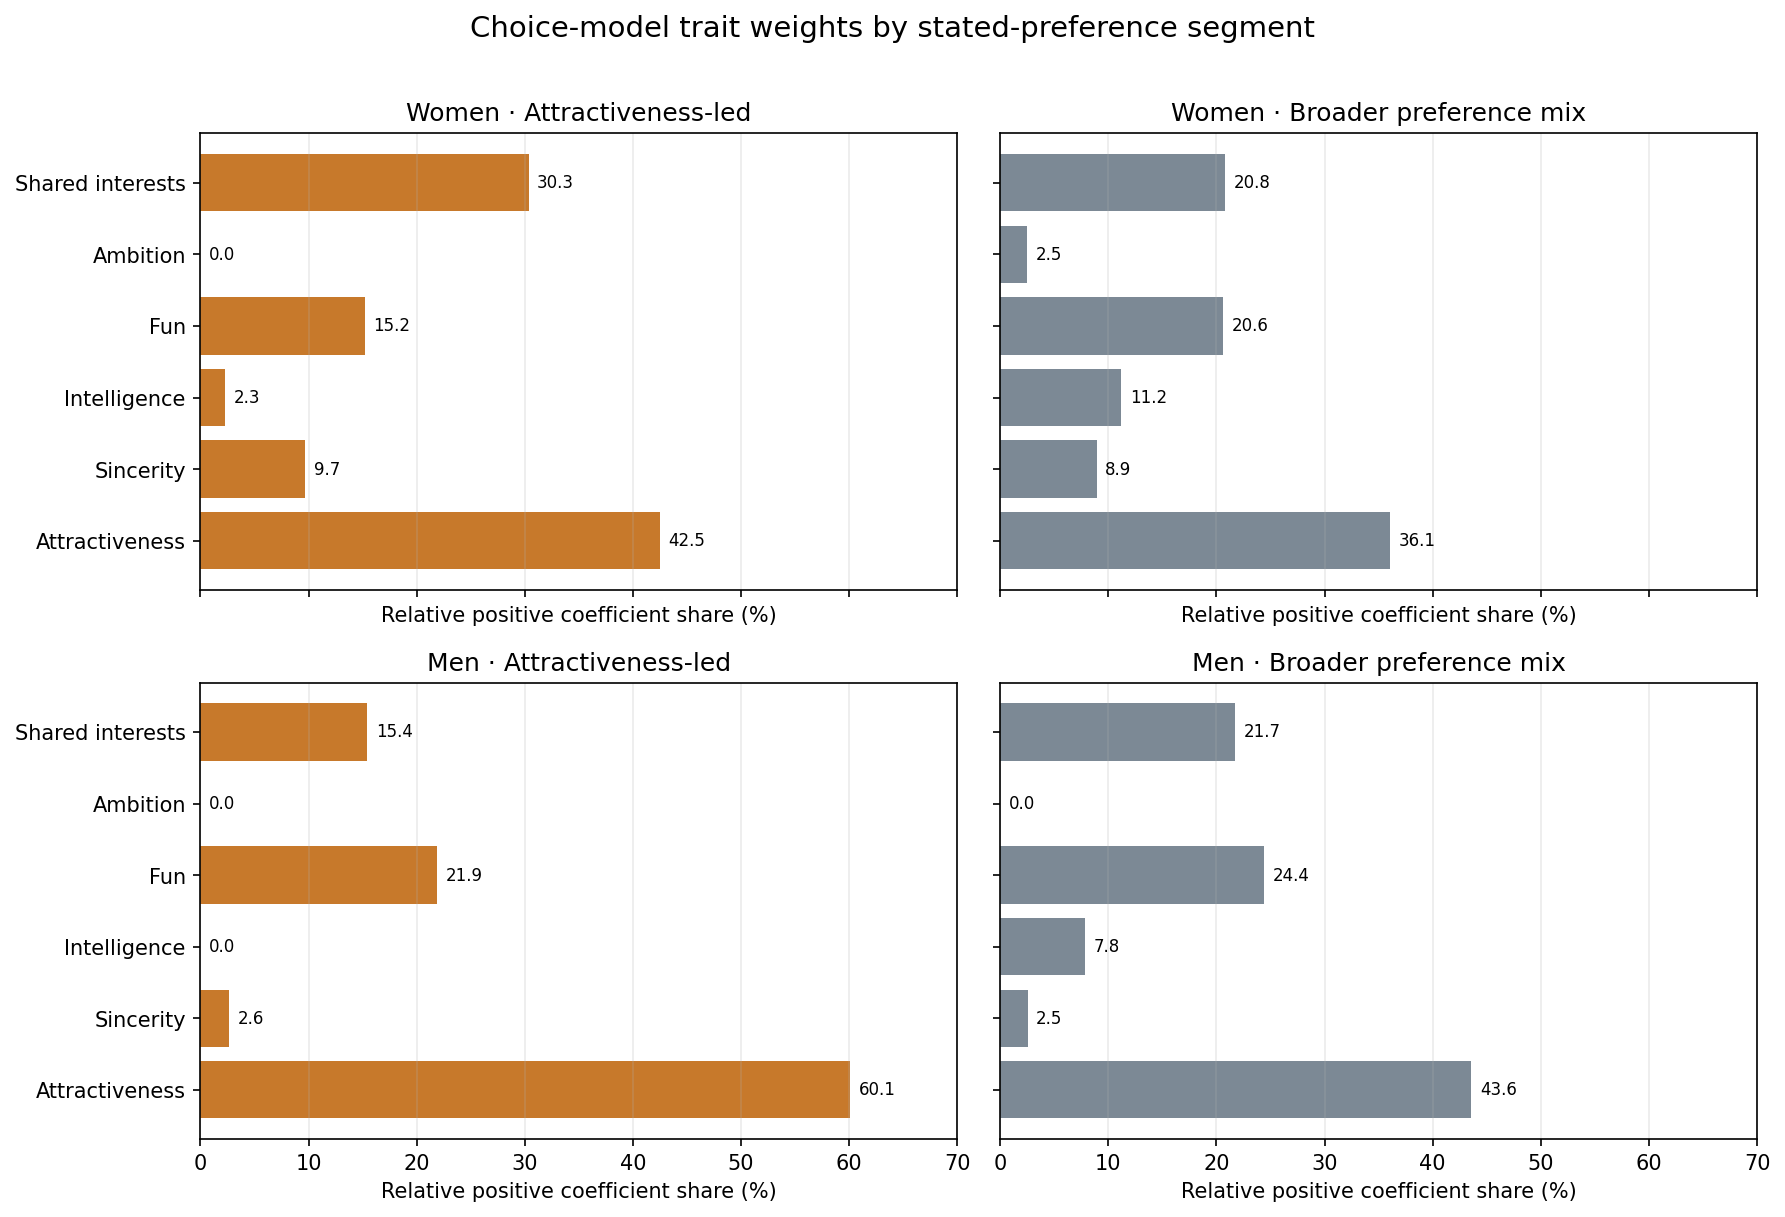

In [7]:
share_plot = segment_results.copy()
groups = [
    ("Women", "Attractiveness-led"),
    ("Women", "Broader preference mix"),
    ("Men", "Attractiveness-led"),
    ("Men", "Broader preference mix"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (gender_name, segment) in zip(axes.flat, groups):
    part = share_plot.loc[
        share_plot["gender"].eq(gender_name) & share_plot["segment"].eq(segment)
    ]
    part = part.set_index("trait").reindex(list(RATING_NAMES.values())).reset_index()
    bars = ax.barh(
        part["trait"],
        part["relative_revealed_weight_pct"],
        color="#C7792B" if segment == "Attractiveness-led" else "#7C8995",
    )
    ax.invert_yaxis()
    ax.set_title(f"{gender_name} · {segment}")
    ax.set_xlim(0, 70)
    ax.set_xlabel("Relative positive coefficient share (%)")
    ax.grid(axis="x", alpha=0.25)
    for bar, value in zip(bars, part["relative_revealed_weight_pct"]):
        ax.text(value + 0.8, bar.get_y() + bar.get_height()/2, f"{value:.1f}", va="center", fontsize=8)
fig.suptitle("Choice-model trait weights by stated-preference segment", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()


## 6. Formal test: do the segment-specific trait effects differ?

Comparing separate coefficient tables is descriptive. For a formal comparison, the pooled conditional-logit model is estimated twice within each gender:

- Shared-effects model: the six rating coefficients are the same for both segments.
- Segment-interaction model: each rating coefficient can differ for the attractiveness-led segment.

A likelihood-ratio test compares the models. There are six added interaction terms, so the test has 6 degrees of freedom. A small p-value indicates that the overall six-trait pattern differs between the stated-preference segments. It does not identify which individual trait difference is statistically significant.


In [8]:
interaction_rows = []
interaction_details = []

for gender_code, gender_name in GENDER_NAMES.items():
    gender_rows, z_cols = scaled_by_gender[gender_code]
    interaction_rows_data = gender_rows.copy()
    segment_flag = interaction_rows_data["segment"].eq("Attractiveness-led").astype(float).to_numpy()

    for rating, z_col in zip(RATINGS, z_cols):
        interaction_rows_data[f"int_{rating}"] = interaction_rows_data[z_col].to_numpy() * segment_flag

    int_cols = [f"int_{rating}" for rating in RATINGS]
    common_groups = make_groups(interaction_rows_data, z_cols)
    interaction_groups = make_groups(interaction_rows_data, z_cols + int_cols)

    common_fit = fit_conditional_logit(common_groups, len(z_cols))
    interaction_fit = fit_conditional_logit(interaction_groups, len(z_cols) + len(int_cols))

    lr_stat = max(0.0, 2 * (common_fit.fun - interaction_fit.fun))
    p_value = chi2.sf(lr_stat, df=len(int_cols))
    interaction_rows.append({
        "gender": gender_name,
        "participants": gender_rows["iid"].nunique(),
        "date_decisions": len(gender_rows),
        "LR_chi2": lr_stat,
        "df": len(int_cols),
        "p_value": p_value,
        "common_model_logLik": -common_fit.fun,
        "interaction_model_logLik": -interaction_fit.fun,
    })

    broad_betas = interaction_fit.x[:len(RATINGS)]
    differences = interaction_fit.x[len(RATINGS):]
    attraction_betas = broad_betas + differences
    for trait, broad_beta, difference, attraction_beta in zip(
        RATING_NAMES.values(), broad_betas, differences, attraction_betas
    ):
        interaction_details.append({
            "gender": gender_name,
            "trait": trait,
            "broader_segment_beta": broad_beta,
            "attractiveness_led_minus_broader": difference,
            "attractiveness_led_beta": attraction_beta,
        })

interaction_test = pd.DataFrame(interaction_rows)
interaction_coefficients = pd.DataFrame(interaction_details)

print("Joint likelihood-ratio tests of segment-by-trait differences:")
print(
    interaction_test[
        ["gender", "participants", "date_decisions", "LR_chi2", "df", "p_value"]
    ].round(4).to_string(index=False)
)
print("\nPooled interaction-model coefficients (log-odds per one gender-specific SD):")
print(interaction_coefficients.round(3).to_string(index=False))


Joint likelihood-ratio tests of segment-by-trait differences:
gender  participants  date_decisions  LR_chi2  df  p_value
 Women           223            3000  12.2465   6   0.0567
   Men           229            3222  16.2899   6   0.0123

Pooled interaction-model coefficients (log-odds per one gender-specific SD):
gender            trait  broader_segment_beta  attractiveness_led_minus_broader  attractiveness_led_beta
 Women   Attractiveness                 1.631                            -0.156                    1.474
 Women        Sincerity                 0.403                            -0.067                    0.336
 Women     Intelligence                 0.505                            -0.424                    0.080
 Women              Fun                 0.930                            -0.401                    0.528
 Women         Ambition                 0.112                            -0.198                   -0.087
 Women Shared interests                 0.941        

## 7. Interpretation for the project

In the fitted results, the relative attractiveness shares were about 42.5% vs 36.1% for attractiveness-led vs broader-preference women, and 60.1% vs 43.6% for the corresponding men's segments. The male segments also show a more distributed pattern for fun and shared interests in the broader-preference group.

The joint interaction test in this dataset gives:
- Women: likelihood-ratio chi-square(6) = 12.25, p = .057. This is suggestive, but just above the conventional .05 threshold.
- Men: likelihood-ratio chi-square(6) = 16.29, p = .012. This is evidence that the overall trait-choice pattern differs between men's stated-preference segments.

### Marketing interpretation
This analysis links segmentation to behavior: it tests whether groups defined by what participants say they value also show different associations between partner traits and yes decisions. That can motivate segment-aware matching or recommendation strategies, but it does not establish that using those segments will improve match outcomes. That would require out-of-sample validation or an experiment.

### Limitations
- The attractiveness-led groups are smaller: approximately 42 women and 56 men remain in the choice-model sample.
- Relative shares are a transformation of positive coefficients, not choice probabilities.
- Ratings are observational and were recorded around the date; the analysis does not establish causal effects.
- The likelihood-ratio p-values are model-based and do not adjust for possible dependence from shared events or partners.
- The results describe this speed-dating sample and should not be assumed to generalize directly to dating-app users.
